# 02 — Perfis de fraude: quem é cada conta da quadrilha e quem os detectores encontram

Na quadrilha simulada há três papéis: a **laranja** recebe o dinheiro das vítimas, o
**intermediário** repassa em cadeia e a **coletora** acumula no fim. Este notebook olha
para cada papel separadamente:

1. que atributos distinguem cada papel das contas legítimas;
2. que papéis cada detector encontra (e se ele confunde vítimas com fraudadores);
3. fichas de contas exemplares, para interpretar os resultados;
4. o mesmo olhar sobre as tipologias de lavagem do AMLworld.

Tudo no cenário `sem_atalhos` (sem os sinais que o gerador embute por construção, ver
`docs/resultados.md`), com a configuração de `configs/experimento.yaml`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.anomaly import DETECTORS
from pixfraud.evaluation import recall_by_group
from pixfraud.experiment import load_experiment_config, load_scenarios, prepare
from pixfraud.features import FEATURE_SETS
from pixfraud.simulation import generate_dataset, load_config, with_overrides
from pixfraud.stats import compare_groups
from pixfraud.visualization import DIVERGING_CMAP, SEQUENTIAL_CMAP, explain_account, plot_value_matrix

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG = ROOT / "configs" / "experimento.yaml"
plt.rcParams.update({"figure.dpi": 110, "axes.titlelocation": "left", "axes.titlesize": 11})

config = load_experiment_config(CONFIG)
cenario = load_scenarios(ROOT / "configs" / "cenarios.yaml")["sem_atalhos"]
accounts, tx = generate_dataset(with_overrides(load_config(CONFIG), cenario))
prepared = prepare(accounts, tx, config)
info = accounts.set_index("account_id")
papel = info["role"].where(~info["is_victim"], "vitima")  # vítimas destacadas das pessoas comuns
papel.value_counts().to_frame("contas")

,contas
role,
normal,1828
vitima,172
comercio,100
laranja,24
intermediario,6
coletor,6


## 1. O que distingue cada papel

Delta de Cliff de cada atributo, comparando as contas de um papel com as contas
**legítimas** (pessoas comuns e comércios). Vermelho: o atributo é maior no papel; azul:
menor; |δ| ≥ 0,47 é efeito grande.

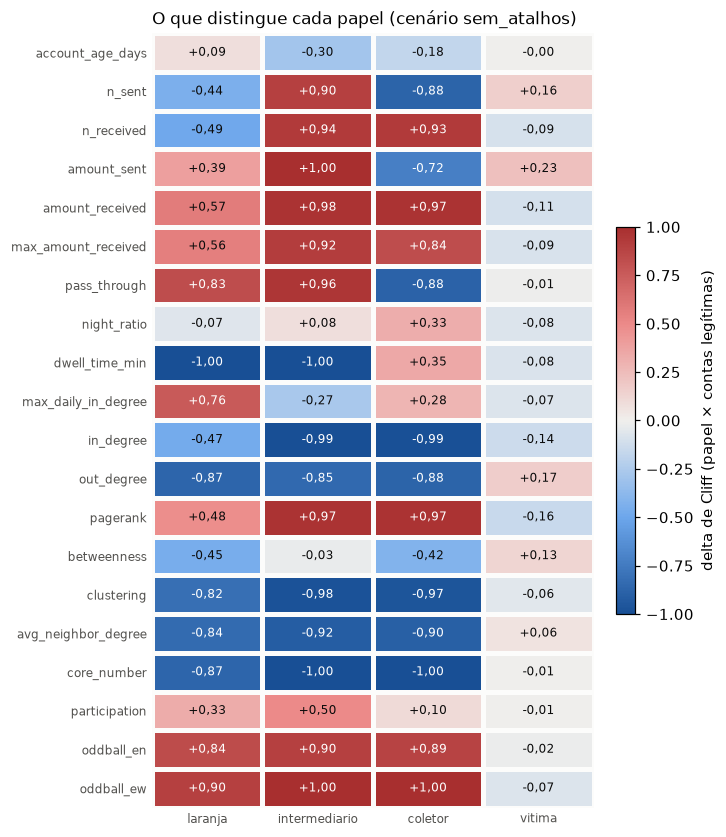

In [2]:
legitimas = papel.isin(["normal", "comercio", "vitima"])
colunas = FEATURE_SETS["completo"]
deltas = {}
for nome in ["laranja", "intermediario", "coletor", "vitima"]:
    grupo = papel[(papel == nome) | (legitimas & (papel != nome))]
    rotulo = (grupo == nome)
    deltas[nome] = compare_groups(prepared.features.loc[grupo.index, colunas], rotulo)["delta de Cliff"]
deltas = pd.DataFrame(deltas).reindex(colunas)

fig, ax = plt.subplots(figsize=(6.5, 7.5), layout="constrained")
mesh = plot_value_matrix(deltas, DIVERGING_CMAP, vmin=-1, vmax=1, fmt="{:+.2f}", ax=ax)
fig.colorbar(mesh, ax=ax, shrink=0.5, label="delta de Cliff (papel × contas legítimas)")
ax.set_title("O que distingue cada papel (cenário sem_atalhos)");

**Leitura.** Cada papel tem uma assinatura própria:

* **laranja**: repassa quase na hora (tempo de permanência δ = −1,00; `pass_through` alto)
  e recebe de várias vítimas que não se conhecem: vizinhança em estrela (`oddball_en`,
  `clustering` baixo, k-núcleo baixo) e pico de pagadores num mesmo dia
  (`max_daily_in_degree`). O **volume** distingue menos do que nos outros papéis
  (δ = 0,57 no valor recebido, contra 0,97 ou mais no intermediário e na coletora);
* **intermediário**: extremo em quase tudo: recebe e repassa muito (δ ≈ 1 em valores e
  `pass_through`), de um único pagador (`in_degree` δ = −0,99), sem esperar;
* **coletora**: recebe muito (`amount_received` δ = 0,97) e **não repassa**
  (`pass_through` δ = −0,88); guarda o dinheiro (tempo de permanência maior);
* **vítima**: não se distingue das pessoas comuns (todos os |δ| < 0,25). É o esperado: uma
  vítima é uma pessoa qualquer que fez um Pix a mais.

## 2. Quem cada detector encontra

Para cada detector e conjunto de atributos, a fração das contas de cada papel que está
entre as *k* mais suspeitas (*k* = nº de contas fraudulentas). A linha `vitima` mostra
quantas **vítimas** aparecem entre as suspeitas: são falsos positivos, e sinalizá-las
seria punir quem perdeu o dinheiro.

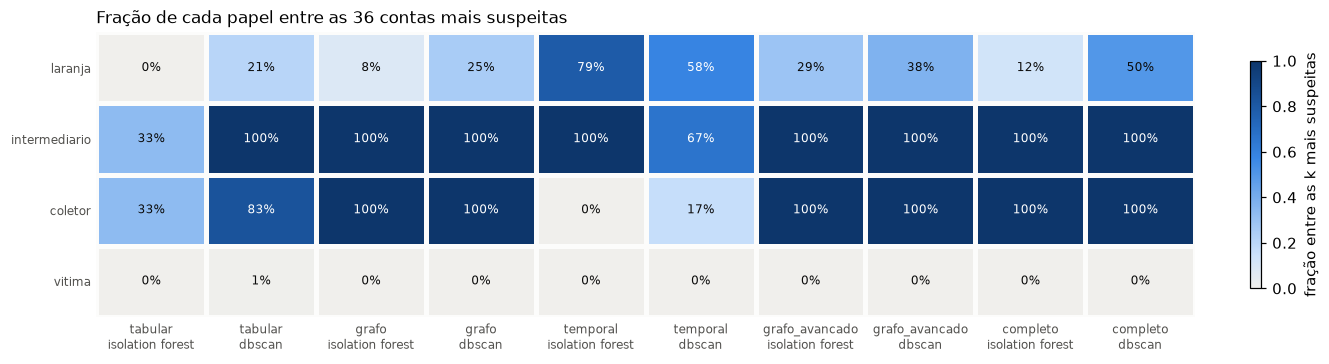

In [3]:
k = int(prepared.labels.sum())
grupos = papel.rename("typology").rename_axis("account_id").reset_index()
grupos = grupos[grupos["typology"].isin(["laranja", "intermediario", "coletor", "vitima"])]
recall = {}
for conjunto in ["tabular", "grafo", "temporal", "grafo_avancado", "completo"]:
    for modelo, detectar in DETECTORS.items():
        escores = detectar(prepared.features[FEATURE_SETS[conjunto]], **config["modelos"][modelo]).scores
        tabela = recall_by_group(grupos, escores, k).set_index("typology")["recall_at_k"]
        recall[f"{conjunto}\n{modelo.replace('_', ' ')}"] = tabela
recall = pd.DataFrame(recall).reindex(["laranja", "intermediario", "coletor", "vitima"])

fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
mesh = plot_value_matrix(recall, SEQUENTIAL_CMAP, vmin=0, vmax=1, fmt="{:.0%}", ax=ax)
fig.colorbar(mesh, ax=ax, shrink=0.8, label="fração entre as k mais suspeitas")
ax.set_title(f"Fração de cada papel entre as {k} contas mais suspeitas");

**Leitura.**

* Os conjuntos com atributos de **grafo** encontram 100% dos intermediários e das
  coletoras: o formato da rede em volta delas é muito incomum.
* As **laranjas são as mais difíceis**. Só os atributos **temporais** encontram a maioria
  (79% com Isolation Forest); o `completo` com DBSCAN encontra metade. É um problema
  justamente porque a laranja é o primeiro salto do dinheiro: é nela que o MED ainda
  consegue devolver algo (ver `docs/resultados.md`, detecção a tempo).
* **Nenhum detector sinaliza vítimas** (0% a 1%), um cuidado importante: tratar a vítima
  como suspeita seria punir quem perdeu o dinheiro.
* O tabular com Isolation Forest não encontra nenhuma laranja: sem os atalhos do gerador,
  os agregados da conta sozinhos não bastam.

## 3. Fichas de contas exemplares

A conta mais suspeita de cada papel segundo o `completo` com DBSCAN. À esquerda, a
vizinhança (as contas com quem ela mais movimentou dinheiro); à direita, o percentil de
cada atributo: barras perto de 0 ou de 1 são os valores extremos que chamaram atenção.

In [4]:
risco = DETECTORS["dbscan"](prepared.features[FEATURE_SETS["completo"]], **config["modelos"]["dbscan"]).scores
grafo = prepared.graph.copy()
nx.set_node_attributes(grafo, papel.to_dict(), "role")
exemplos = {nome: risco[papel[papel == nome].index].idxmax() for nome in ["laranja", "intermediario", "coletor"]}
exemplos

{'laranja': 'C001058', 'intermediario': 'C000286', 'coletor': 'C000995'}

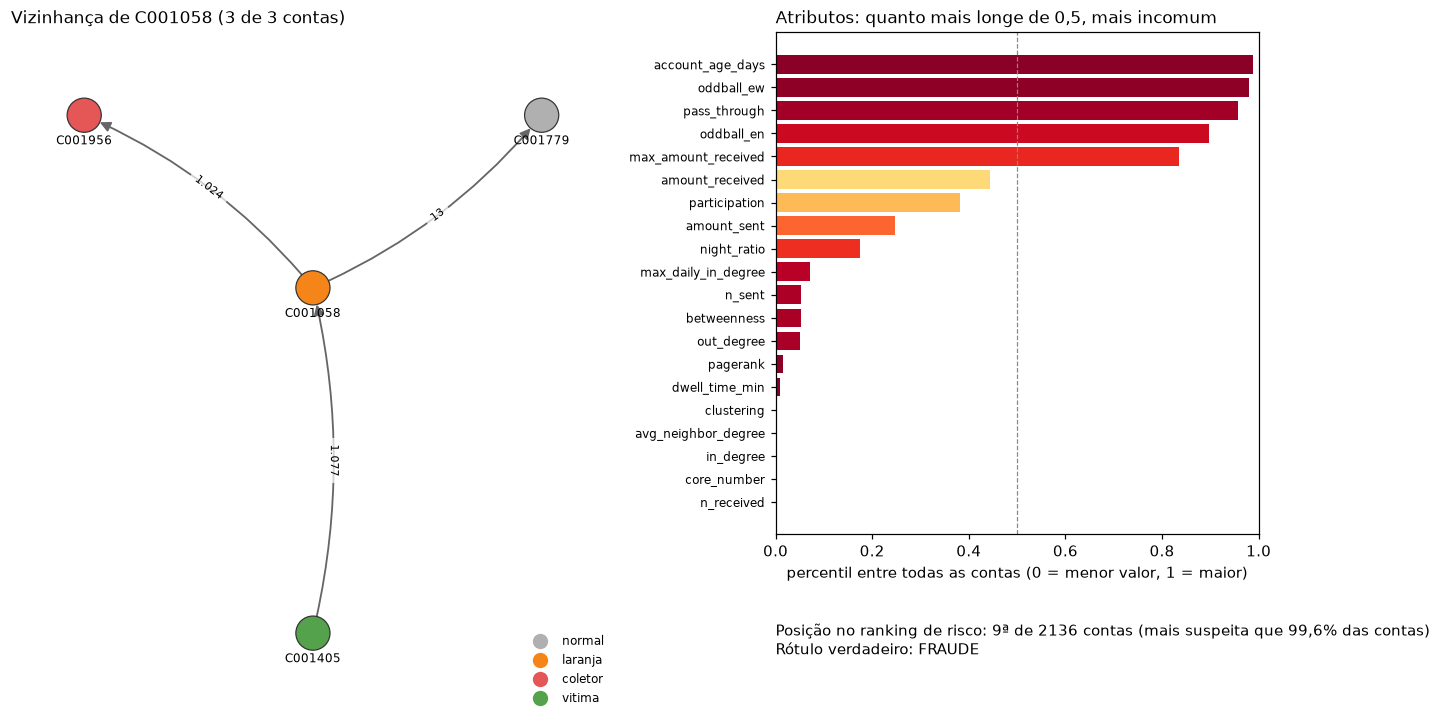

In [5]:
explain_account(grafo, prepared.features[FEATURE_SETS["completo"]], risco, exemplos["laranja"],
                fraud=prepared.labels);

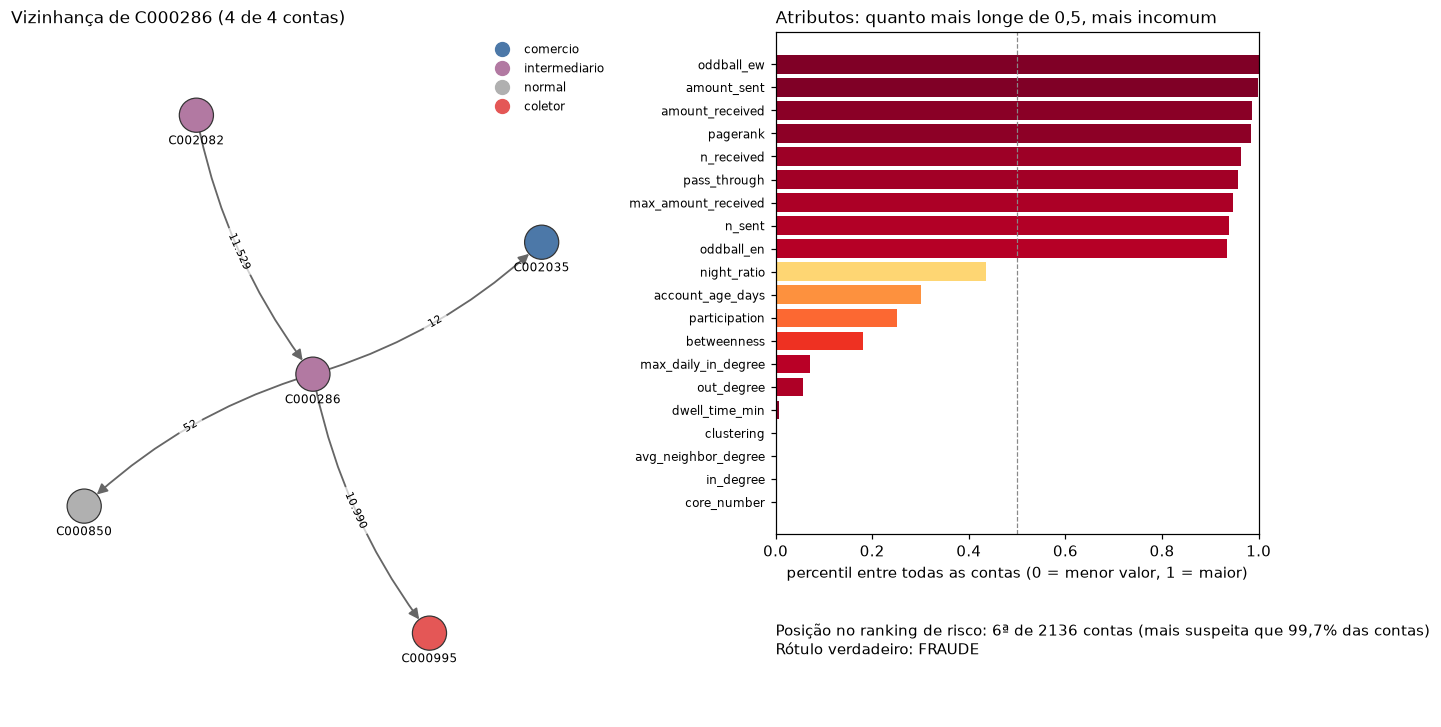

In [6]:
explain_account(grafo, prepared.features[FEATURE_SETS["completo"]], risco, exemplos["intermediario"],
                fraud=prepared.labels);

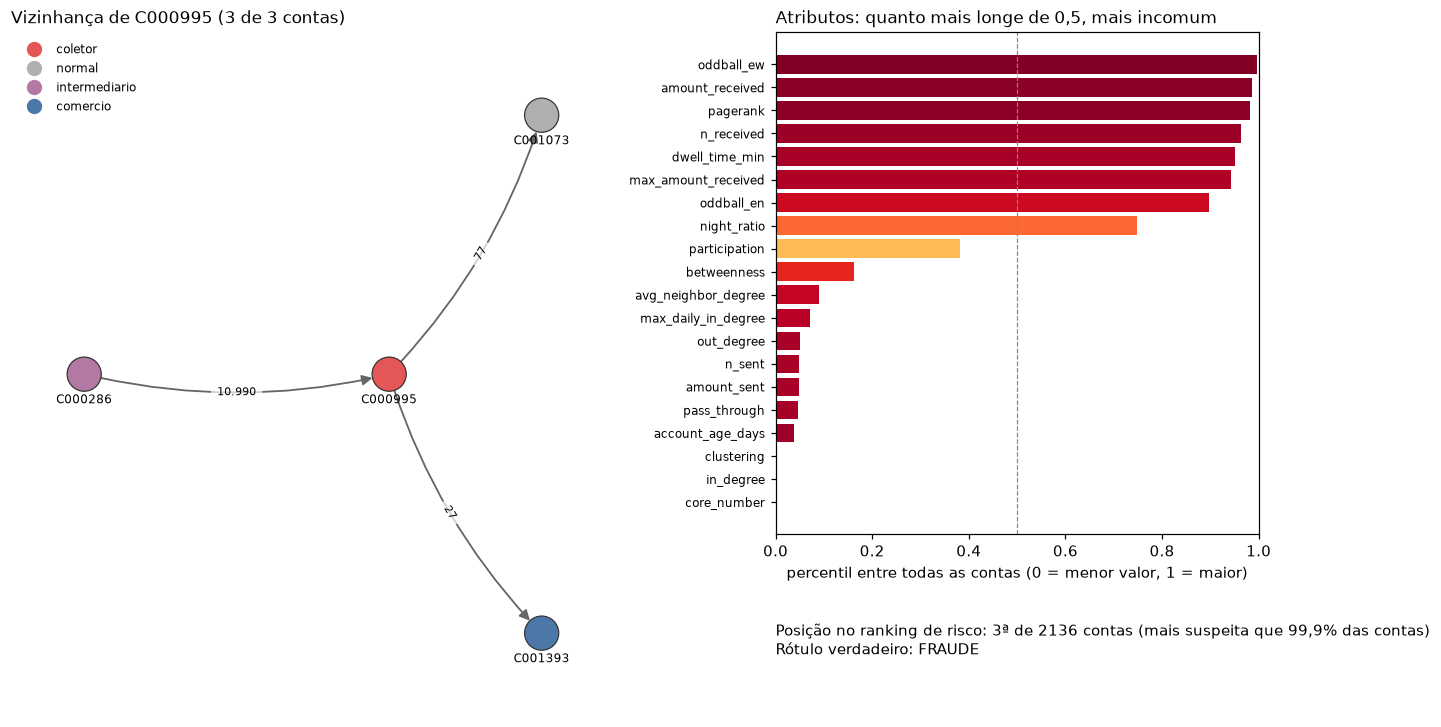

In [7]:
explain_account(grafo, prepared.features[FEATURE_SETS["completo"]], risco, exemplos["coletor"],
                fraud=prepared.labels);

**Leitura.** A laranja recebe o golpe de uma vítima e repassa quase tudo à coletora em
minutos; os atributos extremos (percentil perto de 0 ou de 1) são justamente o
`pass_through`, o tempo de permanência e os de vizinhança. O intermediário e a coletora
aparecem nas pontas da cadeia, com valores extremos em quase todos os atributos. Essas
fichas são o que um analista veria para decidir se bloqueia uma conta.

## 4. Tipologias de lavagem no AMLworld

O mesmo olhar sobre um dataset que não foi gerado por nós: a fração das contas de cada
tipologia de lavagem entre as *k* mais suspeitas, com a mesma configuração, janela a
janela (saída de `scripts/avaliar_externo.py`; ver `data/README.md` para baixar e
importar o AMLworld).

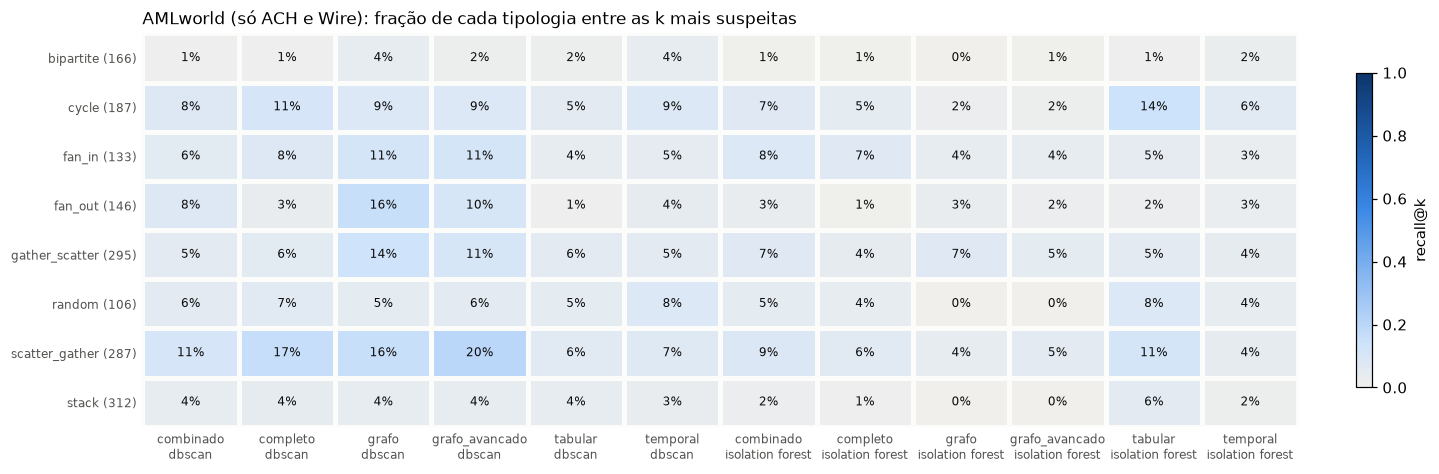

In [8]:
arquivo = ROOT / "reports" / "amlworld" / "results" / "amlworld_pix_tipologias.csv"
if arquivo.exists():
    tipologias = pd.read_csv(arquivo)
    tabela = tipologias.pivot_table(index="typology", columns=["modelo", "atributos"], values="recall_at_k")
    contas = tipologias.groupby("typology")["contas"].max()
    tabela.index = [f"{t} ({contas[t]})" for t in tabela.index]
    tabela.columns = [f"{a}\n{m.replace('_', ' ')}" for m, a in tabela.columns]
    fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
    mesh = plot_value_matrix(tabela, SEQUENTIAL_CMAP, vmin=0, vmax=1, fmt="{:.0%}", ax=ax)
    fig.colorbar(mesh, ax=ax, shrink=0.8, label="recall@k")
    ax.set_title("AMLworld (só ACH e Wire): fração de cada tipologia entre as k mais suspeitas")
else:
    print("Rode scripts/avaliar_externo.py primeiro (ver data/README.md).")

**Leitura.** No AMLworld a tarefa é bem mais difícil: nenhuma combinação encontra mais
de 20% das contas de uma tipologia. As que mais aparecem são as de formato **espalha e
junta** (`scatter_gather`, `gather_scatter`) e **leque** (`fan_out`, `fan_in`), justamente
as que deixam marcas de vizinhança, e quase sempre com atributos de grafo. Cadeias
(`stack`), grupos bipartidos e padrões aleatórios passam quase despercebidos. Parte da
dificuldade pode vir do rótulo: toda conta que enviou ou recebeu uma transação de lavagem
conta como suspeita, mesmo que o resto do seu movimento seja comum (ver
`docs/resultados.md`).

## Conclusões

1. **Grafo e tempo se completam.** A estrutura da rede denuncia intermediários e
   coletoras; o tempo de permanência denuncia as laranjas. Por isso o conjunto `completo`
   é o mais robusto nos cenários.
2. **O ponto fraco são as laranjas**, que são justamente as contas em que o dinheiro
   ainda pode ser recuperado. Melhorar a detecção delas (mais atributos temporais,
   detecção em janelas curtas) é o próximo passo com mais impacto.
3. **As vítimas não viram falsos positivos**, o que é essencial para uso real.
4. Tudo aqui ainda depende das hipóteses do gerador (as laranjas repassam em ~30 min,
   as vítimas não se conhecem). O AMLworld (seção 4) testa o mesmo raciocínio em dados
   de outra origem.